<a href="https://colab.research.google.com/github/kavyaayyappan1998/DATA266---2738/blob/main/Assignment%209/Homework_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install "torch>=2.2" "torchvision>=0.17" "diffusers>=0.30,<1" "transformers>=4.40,<5" "accelerate>=0.28" "safetensors>=0.4" matplotlib pandas tqdm pillow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, random, math, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from diffusers import AutoencoderKL

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "A CUDA GPU is strongly recommended for the required 50-epoch training."
OUT = Path("hw9_outputs"); OUT.mkdir(exist_ok=True)
CONFIG = dict(seed=SEED, image_size=128, latent_size=16, timesteps=1000,
              beta_start=1e-4, beta_end=0.02, epochs=50, lr=2e-5,
              train_batch_size=128, vae_batch_size=64, guidance_scale=7.5,
              label_dropout=0.1, num_workers=2)
print("GPU:", torch.cuda.get_device_name(0))
print(CONFIG)
with open(OUT/"config.json", "w") as f: json.dump(CONFIG,f,indent=2)

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


GPU: Tesla T4
{'seed': 42, 'image_size': 128, 'latent_size': 16, 'timesteps': 1000, 'beta_start': 0.0001, 'beta_end': 0.02, 'epochs': 50, 'lr': 2e-05, 'train_batch_size': 128, 'vae_batch_size': 64, 'guidance_scale': 7.5, 'label_dropout': 0.1, 'num_workers': 2}


1. FashionMNIST and pretrained VAE

In [3]:
tfm = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3,(0.5,)*3),
])
train_ds = datasets.FashionMNIST("data", train=True, download=True, transform=tfm)
test_ds = datasets.FashionMNIST("data", train=False, download=True, transform=tfm)
print("Training:",len(train_ds),"Test:",len(test_ds), "Classes:",train_ds.classes)
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(DEVICE).eval()
vae.requires_grad_(False)
LATENT_SCALE = 0.18215
@torch.no_grad()
def encode_images(x):
    return vae.encode(x.to(DEVICE)).latent_dist.mean * LATENT_SCALE
@torch.no_grad()
def decode_latents(z):
    return vae.decode(z.to(DEVICE) / LATENT_SCALE).sample.clamp(-1,1)
def display_images(x, title="", nrow=8, size=(12,5)):
    grid=make_grid(((x.detach().float().cpu()+1)/2).clamp(0,1), nrow=nrow)
    plt.figure(figsize=size);plt.imshow(grid.permute(1,2,0));plt.axis("off");plt.title(title);plt.show()

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 166kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.14MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.98MB/s]


Training: 60000 Test: 10000 Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

VAE latent shape: (32, 4, 16, 16) Reconstruction MSE: 0.0007897214964032173


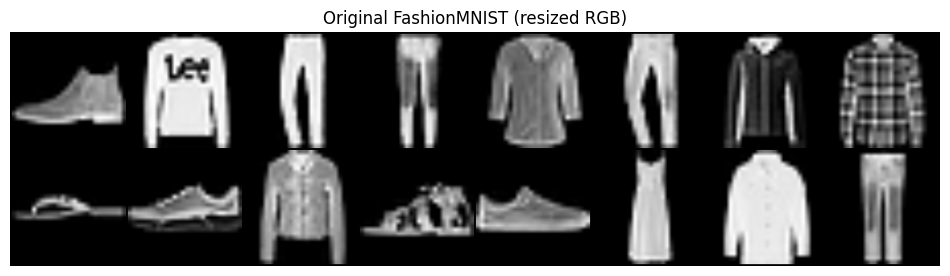

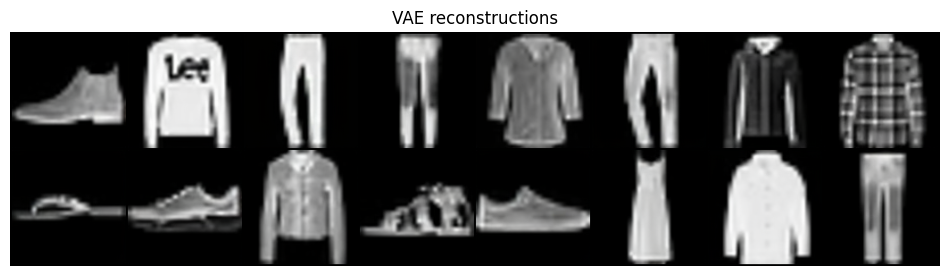

In [4]:
test_loader=DataLoader(test_ds,batch_size=32,shuffle=False,num_workers=CONFIG["num_workers"])
xb,yb=next(iter(test_loader))
with torch.no_grad():
    z=encode_images(xb)
    rec=decode_latents(z).cpu()
mse=F.mse_loss(rec,xb).item()
print("VAE latent shape:",tuple(z.shape),"Reconstruction MSE:",mse)
display_images(xb[:16],"Original FashionMNIST (resized RGB)",8,(12,4))
display_images(rec[:16],"VAE reconstructions",8,(12,4))
pd.DataFrame([{"reconstruction_mse":mse,"latent_shape":str(tuple(z.shape[1:]))}]).to_csv(OUT/"vae_metrics.csv",index=False)

2. Forward diffusion in latent space


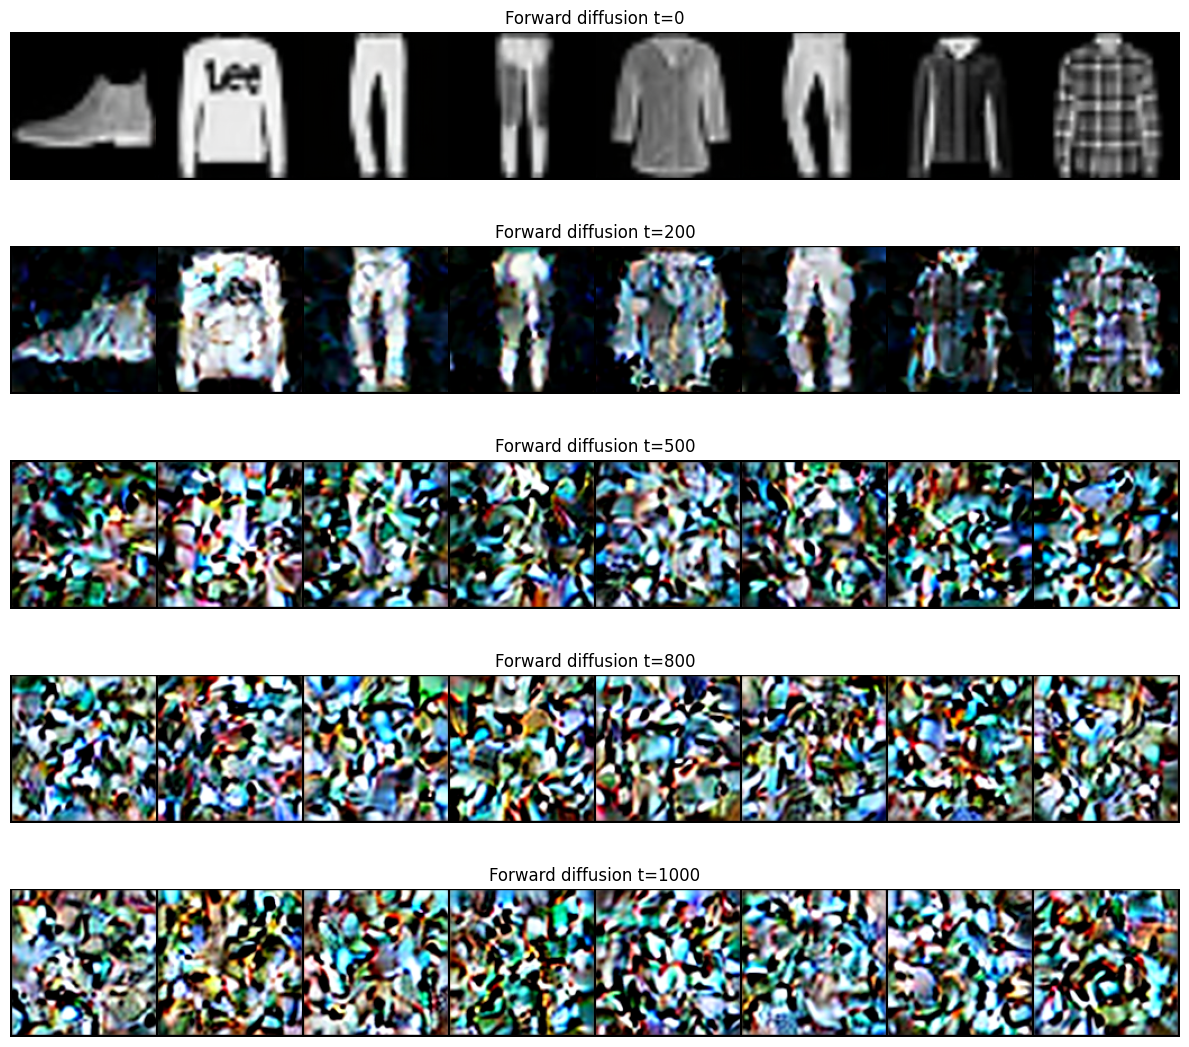

In [5]:
T=CONFIG["timesteps"]
betas=torch.linspace(CONFIG["beta_start"],CONFIG["beta_end"],T,device=DEVICE)
alphas=1-betas
alpha_bars=torch.cumprod(alphas,dim=0)
def extract(a,t,shape):
    return a.gather(0,t).reshape(-1,*([1]*(len(shape)-1)))
def q_sample(z0,t,noise=None):
    if noise is None: noise=torch.randn_like(z0)
    return extract(alpha_bars.sqrt(),t,z0.shape)*z0 + extract((1-alpha_bars).sqrt(),t,z0.shape)*noise
with torch.no_grad():
    z0=encode_images(xb[:8])
    panels=[]
    for label,idx in [(0,0),(200,199),(500,499),(800,799),(1000,999)]:
        zt=q_sample(z0,torch.full((len(z0),),idx,device=DEVICE,dtype=torch.long))
        panels.append((label,decode_latents(zt).cpu()))
fig,axs=plt.subplots(5,1,figsize=(12,11))
for ax,(label,imgs) in zip(axs,panels):
    grid=make_grid((imgs+1)/2,nrow=8)
    ax.imshow(grid.permute(1,2,0));ax.set_title(f"Forward diffusion t={label}");ax.axis("off")
plt.tight_layout();plt.savefig(OUT/"forward_diffusion.png",dpi=160);plt.show()

3. Custom conditional U-Net with residual blocks and self-attention

In [6]:
def gn(ch):
    return nn.GroupNorm(min(32, ch), ch)
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self,dim):
        super().__init__();self.dim=dim
    def forward(self,t):
        half=self.dim//2
        freq=torch.exp(-math.log(10000)*torch.arange(half,device=t.device)/max(half-1,1))
        emb=t.float()[:,None]*freq[None,:]
        return torch.cat([emb.sin(),emb.cos()],dim=-1)
class ResBlock(nn.Module):
    def __init__(self,cin,cout,emb_dim):
        super().__init__()
        self.n1=gn(cin);self.c1=nn.Conv2d(cin,cout,3,padding=1)
        self.emb=nn.Linear(emb_dim,cout)
        self.n2=gn(cout);self.c2=nn.Conv2d(cout,cout,3,padding=1)
        self.skip=nn.Conv2d(cin,cout,1) if cin!=cout else nn.Identity()
    def forward(self,x,e):
        h=self.c1(F.silu(self.n1(x)))
        h=h+self.emb(F.silu(e))[:,:,None,None]
        h=self.c2(F.silu(self.n2(h)))
        return h+self.skip(x)
class Attention(nn.Module):
    def __init__(self,ch,heads=4):
        super().__init__()
        self.norm=gn(ch);self.qkv=nn.Conv2d(ch,ch*3,1)
        self.out=nn.Conv2d(ch,ch,1);self.heads=heads
    def forward(self,x):
        b,c,h,w=x.shape
        q,k,v=self.qkv(self.norm(x)).chunk(3,dim=1)
        def split(t): return t.reshape(b,self.heads,c//self.heads,h*w).transpose(2,3)
        q,k,v=map(split,(q,k,v))
        y=F.scaled_dot_product_attention(q,k,v)
        y=y.transpose(2,3).reshape(b,c,h,w)
        return x+self.out(y)
class ConditionalUNet(nn.Module):
    def __init__(self,base=64,classes=11):
        super().__init__()
        d=base*4
        self.time=nn.Sequential(SinusoidalTimeEmbedding(base),nn.Linear(base,d),nn.SiLU(),nn.Linear(d,d))
        self.labels=nn.Embedding(classes,d)
        self.input=nn.Conv2d(4,base,3,padding=1)
        self.r16=ResBlock(base,base,d);self.a16=Attention(base)
        self.down1=nn.Conv2d(base,base,3,stride=2,padding=1)
        self.r8=ResBlock(base,base*2,d)
        self.down2=nn.Conv2d(base*2,base*2,3,stride=2,padding=1)
        self.r4=ResBlock(base*2,base*4,d)
        self.mid1=ResBlock(base*4,base*4,d);self.midattn=Attention(base*4)
        self.mid2=ResBlock(base*4,base*4,d)
        self.up4=ResBlock(base*8,base*4,d)
        self.up8=ResBlock(base*4+base*2,base*2,d)
        self.up16=ResBlock(base*2+base,base,d);self.upattn=Attention(base)
        self.output=nn.Sequential(gn(base),nn.SiLU(),nn.Conv2d(base,4,3,padding=1))
    def forward(self,x,t,labels):
        e=self.time(t)+self.labels(labels)
        h16=self.a16(self.r16(self.input(x),e))
        h8=self.r8(self.down1(h16),e)
        h4=self.r4(self.down2(h8),e)
        h=self.mid2(self.midattn(self.mid1(h4,e)),e)
        h=self.up4(torch.cat([h,h4],dim=1),e)
        h=F.interpolate(h,scale_factor=2,mode="nearest")
        h=self.up8(torch.cat([h,h8],dim=1),e)
        h=F.interpolate(h,scale_factor=2,mode="nearest")
        h=self.upattn(self.up16(torch.cat([h,h16],dim=1),e))
        return self.output(h)
model=ConditionalUNet().to(DEVICE)
with torch.no_grad():
    check=model(torch.randn(2,4,16,16,device=DEVICE),
                torch.tensor([1,999],device=DEVICE),
                torch.tensor([0,10],device=DEVICE))
assert check.shape==(2,4,16,16)
print("Output shape:",check.shape,"Parameters:",sum(p.numel() for p in model.parameters()))

Output shape: torch.Size([2, 4, 16, 16]) Parameters: 7222980


4. Cache VAE latents and train for 50 epochs

In [7]:
LATENT_CACHE=OUT/"fashionmnist_train_latents.pt"
if LATENT_CACHE.exists():
    cached=torch.load(LATENT_CACHE,map_location="cpu",weights_only=True)
    latents,labels=cached["latents"],cached["labels"]
else:
    loader=DataLoader(train_ds,batch_size=CONFIG["vae_batch_size"],shuffle=False,
                      num_workers=CONFIG["num_workers"],pin_memory=True)
    zz=[];yy=[]
    for imgs,lab in tqdm(loader,desc="Encoding FashionMNIST"):
        with torch.no_grad():
            zz.append(encode_images(imgs).half().cpu())
        yy.append(lab)
    latents=torch.cat(zz);labels=torch.cat(yy)
    torch.save({"latents":latents,"labels":labels},LATENT_CACHE)
assert len(latents)==60000 and latents.shape[1:]==(4,16,16)
print("Cached latents:",latents.shape,latents.dtype)
train_latent_loader=DataLoader(TensorDataset(latents,labels),
    batch_size=CONFIG["train_batch_size"],shuffle=True,
    num_workers=0,pin_memory=True,drop_last=False)

Encoding FashionMNIST:   0%|          | 0/938 [00:00<?, ?it/s]

Cached latents: torch.Size([60000, 4, 16, 16]) torch.float16


Epoch 1/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1: MSE=0.385185


Epoch 2/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2: MSE=0.183374


Epoch 3/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 3: MSE=0.152168


... (90 outputs left out)

Epoch 49/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 49: MSE=0.099787


Epoch 50/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 50: MSE=0.100141


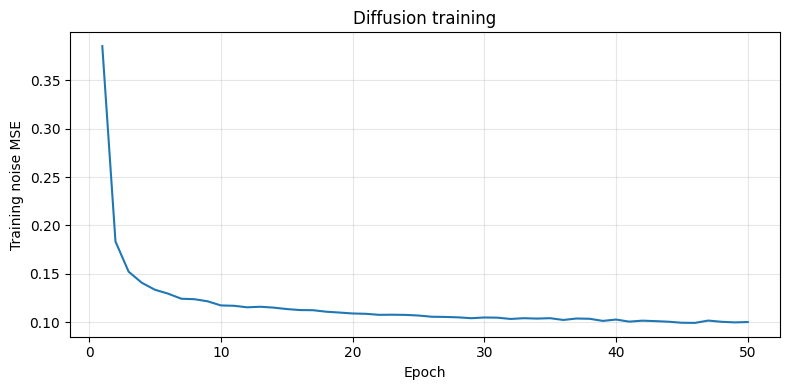

In [8]:
optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG["lr"],weight_decay=0.01)
scaler=torch.amp.GradScaler("cuda",enabled=True)
ckpt_path=OUT/"last_checkpoint.pt"
history=[];start_epoch=0
if ckpt_path.exists():
    state=torch.load(ckpt_path,map_location=DEVICE,weights_only=False)
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    scaler.load_state_dict(state["scaler"])
    start_epoch=state["epoch"]
    history=state["history"]
    print("Resuming from epoch",start_epoch)
for epoch in range(start_epoch,CONFIG["epochs"]):
    model.train();total=0;count=0;start=time.time()
    progress=tqdm(train_latent_loader,desc=f"Epoch {epoch+1}/{CONFIG['epochs']}")
    for z,lab in progress:
        z=z.to(DEVICE,non_blocking=True).float()
        lab=lab.to(DEVICE,non_blocking=True)
        t=torch.randint(0,T,(len(z),),device=DEVICE)
        noise=torch.randn_like(z)
        zt=q_sample(z,t,noise)
        conditioned=lab.clone()
        conditioned[torch.rand(len(lab),device=DEVICE)<CONFIG["label_dropout"]]=10
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda",dtype=torch.float16):
            prediction=model(zt,t,conditioned)
            loss=F.mse_loss(prediction.float(),noise.float())
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        scaler.step(optimizer);scaler.update()
        total+=loss.item()*len(z);count+=len(z)
        progress.set_postfix(loss=f"{total/count:.4f}")
    mean_loss=total/count
    history.append({"epoch":epoch+1,"train_noise_mse":mean_loss,
                    "seconds":round(time.time()-start,1)})
    pd.DataFrame(history).to_csv(OUT/"training_history.csv",index=False)
    torch.save({"epoch":epoch+1,"model":model.state_dict(),
                "optimizer":optimizer.state_dict(),"scaler":scaler.state_dict(),
                "history":history},ckpt_path)
    print(f"Epoch {epoch+1}: MSE={mean_loss:.6f}")
torch.save(model.state_dict(),OUT/"conditional_unet_final.pt")
plt.figure(figsize=(8,4));plt.plot([h["epoch"] for h in history],
    [h["train_noise_mse"] for h in history])
plt.xlabel("Epoch");plt.ylabel("Training noise MSE");plt.title("Diffusion training")
plt.grid(alpha=.3);plt.tight_layout();plt.savefig(OUT/"training_curve.png");plt.show()

5. Conditional and unconditional DDPM sampling with classifier-free guidance

DDPM sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

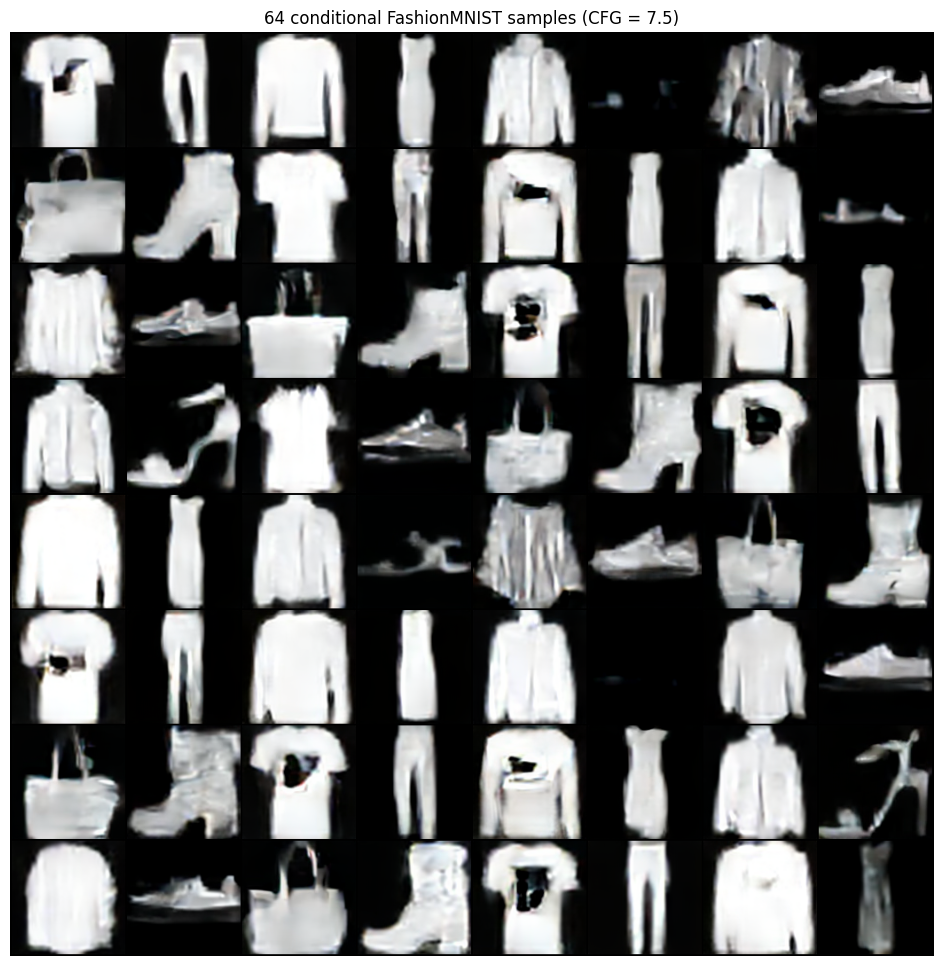

Saved: hw9_outputs/conditional_samples_64.png


In [9]:
@torch.no_grad()
def sample_ddpm(model,labels,guidance=7.5):
    model.eval()
    labels=labels.to(DEVICE).long()
    x=torch.randn(len(labels),4,16,16,device=DEVICE)
    null_labels=torch.full_like(labels,10)
    for i in tqdm(reversed(range(T)),total=T,desc="DDPM sampling"):
        t=torch.full((len(labels),),i,device=DEVICE,dtype=torch.long)
        with torch.autocast("cuda",dtype=torch.float16):
            eps_cond=model(x,t,labels).float()
            eps_uncond=model(x,t,null_labels).float()
        eps=eps_uncond+guidance*(eps_cond-eps_uncond)
        beta=betas[i];alpha=alphas[i];abar=alpha_bars[i]
        mean=(x-beta/torch.sqrt(1-abar)*eps)/torch.sqrt(alpha)
        if i>0:
            abar_prev=alpha_bars[i-1]
            variance=beta*(1-abar_prev)/(1-abar)
            x=mean+torch.sqrt(variance)*torch.randn_like(x)
        else:
            x=mean
    return x
class_labels=torch.arange(64,device=DEVICE)%10
generated_latents=sample_ddpm(model,class_labels,CONFIG["guidance_scale"])
with torch.no_grad():
    generated=torch.cat([decode_latents(chunk).cpu()
                         for chunk in generated_latents.split(16)])
display_images(generated,"64 conditional FashionMNIST samples (CFG = 7.5)",8,(12,12))
save_image(((generated+1)/2).clamp(0,1),OUT/"conditional_samples_64.png",nrow=8)
torch.save({"samples":generated_latents.cpu(),"labels":class_labels.cpu()},
           OUT/"sample_latents.pt")
print("Saved:",OUT/"conditional_samples_64.png")

6. Evaluation and analysis

In [10]:
@torch.no_grad()
def evaluate_noise_mse(ds,max_batches=20):
    loader=DataLoader(ds,batch_size=32,shuffle=False,num_workers=2)
    model.eval();total=0;count=0
    for batch_idx,(imgs,lab) in enumerate(tqdm(loader,desc="Held-out evaluation")):
        if batch_idx>=max_batches: break
        z=encode_images(imgs).float()
        lab=lab.to(DEVICE)
        t=torch.randint(0,T,(len(z),),device=DEVICE)
        eps=torch.randn_like(z)
        pred=model(q_sample(z,t,eps),t,lab).float()
        total+=F.mse_loss(pred,eps,reduction="sum").item()
        count+=eps.numel()
    return total/count
test_noise_mse=evaluate_noise_mse(test_ds)
summary={"vae_reconstruction_mse":mse,"heldout_noise_mse":test_noise_mse,
         "epochs_completed":len(history),"final_train_noise_mse":history[-1]["train_noise_mse"],
         "guidance_scale":CONFIG["guidance_scale"]}
print(pd.Series(summary))
with open(OUT/"summary_metrics.json","w") as f: json.dump(summary,f,indent=2)

Held-out evaluation:   0%|          | 0/313 [00:00<?, ?it/s]

vae_reconstruction_mse     0.000790
heldout_noise_mse          0.094273
epochs_completed          50.000000
final_train_noise_mse      0.100141
guidance_scale             7.500000
dtype: float64


7. Conclusion

This notebook implemented a complete latent diffusion pipeline on FashionMNIST, following the Stable Diffusion recipe at small scale.

Pipeline summary

The pretrained Stable Diffusion VAE (sd-vae-ft-mse) compressed 128×128 RGB images to 4×16×16 latents (64× fewer values) with a reconstruction MSE of 0.00079, confirming that diffusion can be run in latent space with negligible loss of visual information.
The forward process with 1,000 linear-β steps (1e-4 → 0.02) was visualised at t = 0, 200, 500, 800, 1000. Garment structure survives to t ≈ 200 and is fully destroyed by t = 500, so the schedule covers the data distribution with margin.
A custom conditional U-Net (base 64, multipliers 1/2/4, sinusoidal time embedding, GroupNorm + SiLU residual blocks, self-attention at 16×16 and the 4×4 bottleneck, 11-entry label embedding with 10% null dropout) was trained for 50 epochs at lr 2e-5. The noise-prediction MSE dropped from 0.385 to 0.100, with held-out test MSE of 0.094, indicating stable convergence and no overfitting.
DDPM sampling with classifier-free guidance (s = 7.5) produced a 64-image grid in which every sample matches its target class; shoes, bags and trousers are sharpest, while T-shirts show a dark logo-like artefact and sandals are the least detailed. Samples within a class differ in shape and shading, so guidance improved class fidelity without collapsing diversity.

Key takeaways

Latent-space diffusion is far cheaper than pixel-space diffusion (16×16 vs 128×128 inputs, ~34 s per epoch) while still producing recognisable, class-consistent images.
Classifier-free guidance, enabled by simple label dropout during training, is sufficient for strong conditional control with no separate classifier.
The training curve was still decreasing at epoch 50, so the mandated low learning rate is the main limit on sample sharpness rather than the architecture.